In [1]:
# Imports
import torch
import torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader

import os
import random 
import matplotlib.pyplot as plt
from collections import defaultdict

# **1. Assembling the joint dataset**

In [2]:
transform = T.ToTensor() # Converts to Torch Tensor (C, H, W) so it can be later trained on

mnist = torchvision.datasets.MNIST(root='./data', download=True, transform=transform)  # Note this is only the 'training' data
svhn = torchvision.datasets.SVHN(root='./data', download=True, transform=transform)    # Note this is only the 'training' data

print(len(mnist))
print(len(svhn))

60000
73257


Get the indices per label of each dataset.

In [3]:
mnist_indices = defaultdict(list)
svhn_indices = defaultdict(list)

for i, label in enumerate(mnist.targets):
    mnist_indices[int(label)].append(i)

for i, label in enumerate(svhn.labels):
    svhn_indices[label].append(i)

print(mnist_indices[0])
print(svhn_indices[0])

[1, 21, 34, 37, 51, 56, 63, 68, 69, 75, 81, 88, 95, 108, 114, 118, 119, 121, 156, 169, 192, 206, 209, 210, 216, 229, 232, 234, 246, 249, 260, 283, 293, 296, 303, 320, 326, 359, 399, 427, 429, 435, 440, 451, 453, 458, 462, 464, 473, 489, 519, 524, 526, 527, 542, 577, 582, 596, 603, 612, 633, 639, 656, 662, 666, 667, 668, 669, 689, 702, 709, 712, 733, 743, 745, 776, 781, 787, 790, 818, 825, 849, 859, 860, 869, 872, 889, 903, 927, 943, 949, 952, 957, 965, 979, 984, 997, 1000, 1015, 1018, 1028, 1029, 1040, 1046, 1049, 1076, 1078, 1090, 1093, 1102, 1107, 1128, 1137, 1152, 1168, 1179, 1195, 1209, 1268, 1304, 1310, 1346, 1349, 1359, 1363, 1367, 1368, 1371, 1372, 1377, 1386, 1387, 1403, 1423, 1443, 1454, 1471, 1479, 1489, 1495, 1501, 1502, 1512, 1517, 1530, 1532, 1571, 1578, 1590, 1596, 1600, 1605, 1606, 1625, 1626, 1645, 1664, 1678, 1682, 1701, 1709, 1712, 1723, 1725, 1729, 1742, 1769, 1771, 1775, 1796, 1797, 1798, 1819, 1828, 1837, 1857, 1868, 1876, 1877, 1897, 1904, 1907, 1916, 1926, 1927, 

Calculating the number of pairs per number.

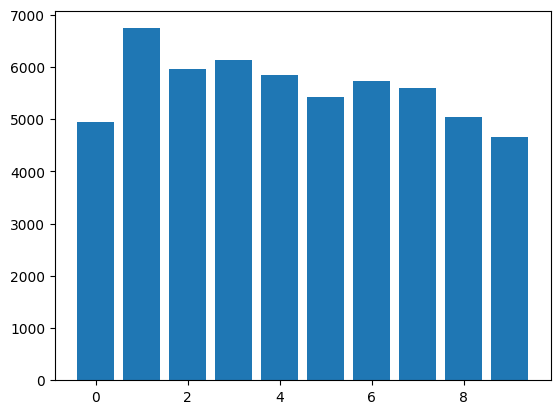

In [4]:
n_pairs = {
    digit: min(len(mnist_indices[digit]), len(svhn_indices[digit]))
    for digit in range(10)
}

plt.bar(n_pairs.keys(), n_pairs.values())
plt.show()

We decided not to balance the classes so far, since there are no big differences. Now we combine the datasets into tuples of indexes and their shared label.

In [5]:
pairs = []

for digit in range(10):
    mnist_idx = mnist_indices[digit].copy()
    svhn_idx = svhn_indices[digit].copy()

    # Shuffle to avoid bias
    random.shuffle(mnist_idx)
    random.shuffle(svhn_idx)

    n = n_pairs[digit]

    for mnist_idx, svhn_idx in zip(mnist_idx[:n], svhn_idx[:n]):
        pairs.append((mnist_idx, svhn_idx, digit))

print(pairs)

[(32221, 8961, 0), (2582, 44880, 0), (28971, 58318, 0), (12239, 4182, 0), (7548, 20433, 0), (25390, 36819, 0), (41288, 69044, 0), (44844, 52931, 0), (666, 30751, 0), (49208, 67963, 0), (33367, 12813, 0), (37822, 64295, 0), (4565, 44504, 0), (14890, 52200, 0), (25065, 42820, 0), (57435, 70236, 0), (56388, 38250, 0), (44951, 12870, 0), (2310, 25168, 0), (31367, 69773, 0), (6146, 3727, 0), (1093, 12773, 0), (26619, 32254, 0), (10245, 16590, 0), (47914, 54079, 0), (9222, 41273, 0), (15491, 68887, 0), (15133, 26972, 0), (45557, 68297, 0), (19072, 52827, 0), (33173, 51936, 0), (58617, 64984, 0), (9823, 40947, 0), (42483, 68581, 0), (5344, 1002, 0), (50749, 59086, 0), (4325, 61395, 0), (38663, 34320, 0), (43367, 31854, 0), (19439, 73220, 0), (34152, 36347, 0), (24308, 22873, 0), (15454, 21729, 0), (38025, 19276, 0), (34381, 14393, 0), (12839, 69572, 0), (19543, 14718, 0), (30871, 19892, 0), (19822, 55954, 0), (47997, 17408, 0), (10974, 49233, 0), (57261, 56916, 0), (31361, 22892, 0), (41320, 

Now we create a combained pytorch dataset with both images and their label.

In [6]:
class CombinedDataset(Dataset):
    def __init__(self, mnist, svhn, pairs):
        self.mnist = mnist
        self.svhn = svhn
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        mnist_idx, svhn_idx, label = self.pairs[idx]

        img_mnist, _ = self.mnist[mnist_idx]
        img_svhn, _ = self.svhn[svhn_idx]

        return img_mnist, img_svhn, label

Label: 0


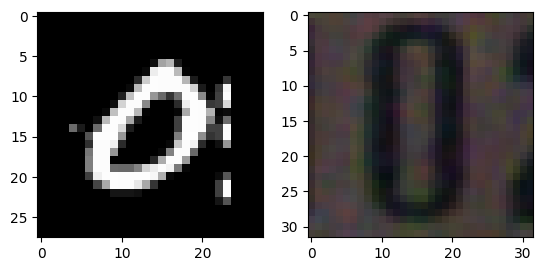

In [7]:
combined = CombinedDataset(mnist, svhn, pairs)

img_mnist, img_svhn, label = combined[0]
print('Label:', label)
plt.subplot(1, 2, 1)
plt.imshow(img_mnist.squeeze(), cmap = 'gray')
plt.subplot(1, 2, 2)
plt.imshow(img_svhn.permute(1,2,0))
plt.show()

In [8]:
img_mnist.shape

torch.Size([1, 28, 28])

In [9]:
# Initializing the corresponding classes
from Nets import Encoder, Decoder, multiviewVAE
from architecture import mnist_encoder_conv_stack,mnist_decoder_conv_stack, shvn_decoder_conv_stack, shvn_encoder_conv_stack, encoder_linear_stack, decoder_linear_stack

latent_dim = 20

# Initializing encoder
encoder1 = Encoder(
    latent_dim, mnist_encoder_conv_stack(), encoder_linear_stack(latent_dim)
)
encoder2 = Encoder(
    latent_dim, shvn_encoder_conv_stack(), encoder_linear_stack(latent_dim)
)

# Initializing decoder
decoder1 = Decoder(
    mnist_decoder_conv_stack(),
    decoder_linear_stack(latent_dim),
    channels=256,
    height=1,
    width=1,
)
decoder2 = Decoder(
    shvn_decoder_conv_stack(),
    decoder_linear_stack(latent_dim),
    channels=256,
    height=1,
    width=1,
)

# Initializing multi-viewVAE
vae = multiviewVAE(
    encoder1=encoder1,
    encoder2=encoder2,
    decoder1=decoder1,
    decoder2=decoder2,
    var_x1=0.1, # May be adjusted depending on if we prioritize KL or not
    var_x2=0.1,
)


In [10]:
# Train on GPU if possible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vae  = vae.to(device)

# Training Loop
dataloader = DataLoader(combined, batch_size=128, shuffle=True)

history = vae.train_loop(dataloader, lr=1e-3, epochs=20, device=device)

Epoch 1 | ELBO loss: -160.8575888766243 |Log-Likelihood 336.2498895388801 | KL1 2.2267223167156796 | KL2 12.307991478999478 
Epoch 2 | ELBO loss: -266.6686457675247 |Log-Likelihood 562.7802901213696 | KL1 10.949018750484006 | KL2 18.493978682846034 
Epoch 3 | ELBO loss: -319.2381073901756 |Log-Likelihood 680.8266113559315 | KL1 20.304980658181435 | KL2 22.045417742196953 
Epoch 4 | ELBO loss: -341.3373458966579 |Log-Likelihood 727.9182689206203 | KL1 22.260263399545586 | KL2 22.983314948635925 
Epoch 5 | ELBO loss: -353.1497749902121 |Log-Likelihood 753.5488029601634 | KL1 22.71519840822676 | KL2 24.534051838659753 
Epoch 6 | ELBO loss: -360.14504097697403 |Log-Likelihood 768.3182709504912 | KL1 23.018140201959632 | KL2 25.010048155904087 
Epoch 7 | ELBO loss: -365.1232421457903 |Log-Likelihood 778.6163323126513 | KL1 23.138193921239065 | KL2 25.2316554814645 
Epoch 8 | ELBO loss: -369.8766635208304 |Log-Likelihood 789.1526319638472 | KL1 23.48083878432428 | KL2 25.9184629792233 
Epoch

In [11]:
# Saving model weights
os.makedirs("./checkpoints", exist_ok=True)
weight_path = "./checkpoints/multiview_vae.pth"
torch.save(vae.state_dict(), weight_path)

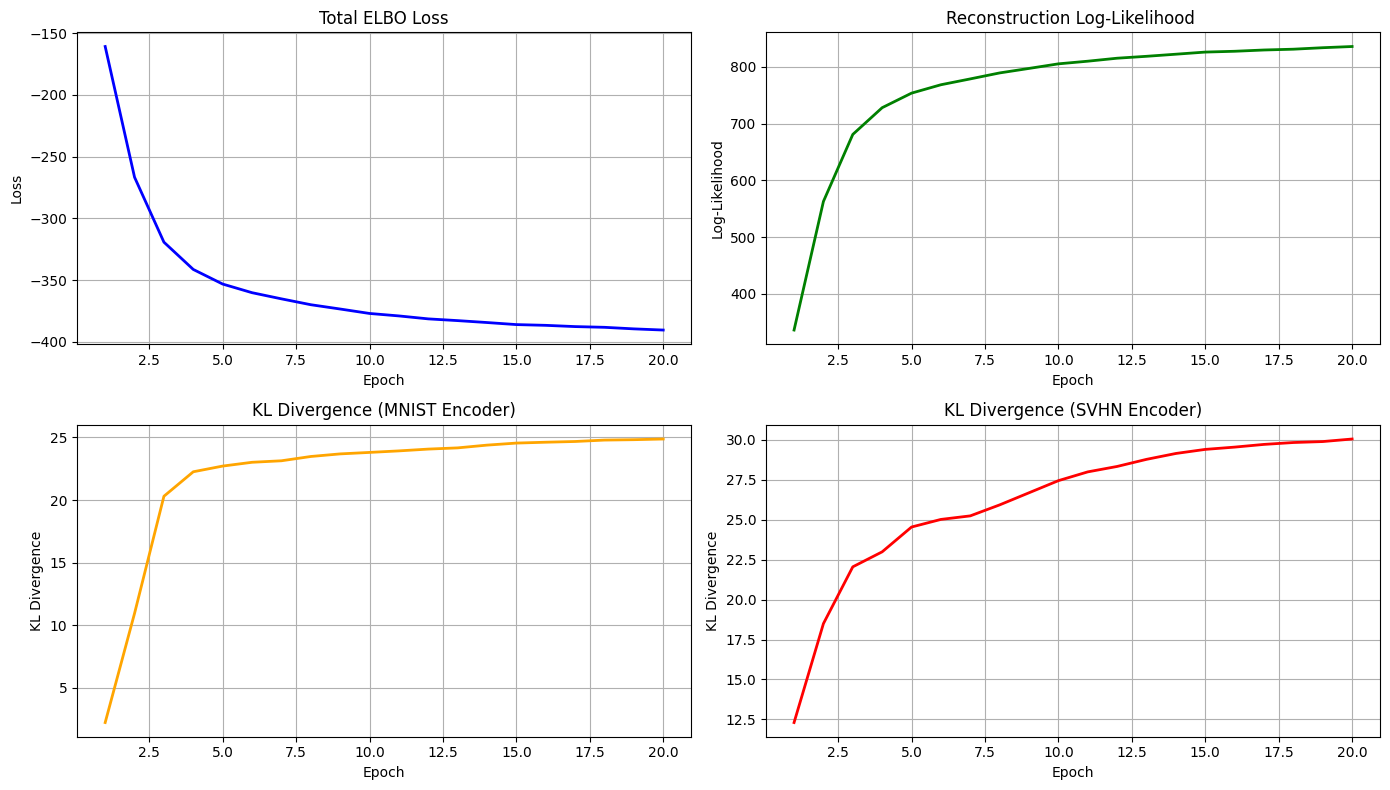

In [12]:
# Plotting training losses
epochs_range = range(1, len(history["elbo"]) + 1)

plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.plot(epochs_range, history["elbo"], color="blue", linewidth=2)
plt.title("Total ELBO Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.subplot(2, 2, 2)
plt.plot(epochs_range, history["rec"], color="green", linewidth=2)
plt.title("Reconstruction Log-Likelihood ")
plt.xlabel("Epoch")
plt.ylabel("Log-Likelihood")
plt.grid(True)

plt.subplot(2, 2, 3)
plt.plot(epochs_range, history["kl1"], color="orange", linewidth=2)
plt.title("KL Divergence (MNIST Encoder)")
plt.xlabel("Epoch")
plt.ylabel("KL Divergence")
plt.grid(True)

plt.subplot(2, 2, 4)
plt.plot(epochs_range, history["kl2"], color="red", linewidth=2)
plt.title("KL Divergence (SVHN Encoder)")
plt.xlabel("Epoch")
plt.ylabel("KL Divergence")
plt.grid(True)

plt.tight_layout()
plt.show()